## Run in Colab or Jupyter
Use a fresh **Python 3.12 CPU runtime** (Runtime → Change runtime type; select **2026.07** if needed), then **Run all**. If setup requests it, restart the session once and run all again. Setup downloads checksum-verified helper release **0.1.0** and installs pinned dependencies. NB-01 reuses the published triangle fixture. No new synthetic observations are generated.

The outputs below are the previously reviewed reader results. Rerunning replaces them with your execution results.

In [ ]:
# Versioned helper setup: run before the teaching cells.
import hashlib, importlib.metadata, io, os, pathlib, subprocess, sys, tempfile, urllib.request, zipfile
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Select a Python 3.12 runtime before running this release.")
release_url = 'https://github.com/sherandoresearch/power-markets-notebooks/releases/download/book-labs-v0.1.0/book-labs-v0.1.0.zip'
expected_sha256 = 'c133ed6a5782865b564c1619bfcc2c9e42274eda343480102236a9fafaabb76d'
local_archive = os.environ.get("BOOK_LABS_RELEASE_ZIP")
archive_bytes = pathlib.Path(local_archive).read_bytes() if local_archive else urllib.request.urlopen(release_url, timeout=90).read()
if hashlib.sha256(archive_bytes).hexdigest() != expected_sha256:
    raise ValueError("Helper release checksum mismatch")
root = pathlib.Path(tempfile.mkdtemp(prefix="power-book-labs-0.1.0-"))
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    for info in archive.infolist():
        member = pathlib.PurePosixPath(info.filename)
        if member.is_absolute() or ".." in member.parts or (info.external_attr >> 16) & 0o170000 == 0o120000:
            raise ValueError("Unsafe helper archive member")
    if sum(i.file_size for i in archive.infolist()) > 10_000_000:
        raise ValueError("Helper archive too large")
    archive.extractall(root)
requirements = (root / "requirements.txt").read_text().splitlines()
modules = {"PyYAML": "yaml"}
restart_required = []
for requirement in requirements:
    package, version = requirement.split("==")
    module = modules.get(package, package)
    if module in sys.modules and importlib.metadata.version(package) != version:
        restart_required.append(package)
subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "-r", str(root / "requirements.txt")])
if restart_required:
    raise RuntimeError("Dependencies installed. Restart session, then Run all again: " + ", ".join(restart_required))
for requirement in requirements:
    package, version = requirement.split("==")
    if importlib.metadata.version(package) != version:
        raise RuntimeError("Dependency version mismatch: " + package)
# Remove a previous run's helper modules when rerunning setup in the same kernel.
for module in list(sys.modules):
    if module == "book_labs" or module.startswith("book_labs."):
        del sys.modules[module]
sys.path.insert(0, str(root / "src"))
os.environ["BOOK_LABS_ROOT"] = str(root)
print("Helper release 0.1.0 verified and ready.")


# NB-01 — One triangle: flows, dispatch, and prices
Companion to Volume I §§4–6. Requires basic matrix multiplication and LP
duality. Reproduce the existing equal-reactance model and the published
300 MW base case; no new synthetic scenario is introduced.

Line order is 1→2, 1→3, 2→3. Positive injection means generation minus load.
Prices are USD/MWh, flows MW, and cost USD for a one-hour interval.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
root = Path(os.environ['BOOK_LABS_ROOT'])
sys.path.insert(0, str(root/'src'))
from book_labs.triangle import operators, flow, dispatch
from book_labs.runtime import setup_plot, record
A, W, psi = operators()
print('Slack-free PTDF, rows [1→2, 1→3, 2→3]:\n', psi.round(6))
transaction = np.array([1., 0., -1.])
print('Published 1 MW transfer:', flow(transaction))
np.testing.assert_allclose(flow(transaction), [1/3, 2/3, 1/3])
np.testing.assert_allclose(A.T @ flow(transaction), transaction, atol=1e-10)

Slack-free PTDF, rows [1→2, 1→3, 2→3]:
 [[ 0.333333 -0.333333  0.      ]
 [ 0.333333 -0.       -0.333333]
 [-0.        0.333333 -0.333333]]
Published 1 MW transfer: [0.33333333 0.66666667 0.33333333]


## Dispatch the published congested base case
Bus 3 consumes 300 MW. Generators at buses 1 and 2 offer at $10 and $30/MWh.
Only line 1–3 is limited, to 150 MW. The expensive generator creates
counterflow relative to bus 1's supply, allowing the load to be served.

In [2]:
result = dispatch()
for key, value in result.items():
    print(key, np.round(value, 6))
np.testing.assert_allclose(result['generation_mw'], [150,150], atol=1e-8)
np.testing.assert_allclose(result['lmp_usd_mwh'], [10,30,50], atol=1e-8)
assert abs(result['signed_dual']-60)<1e-8
# Reference-bus changes alter the decomposition, not balanced flows.
for reference in range(3):
    keep = [i for i in range(3) if i != reference]
    theta = np.zeros(3)
    lap = A.T @ W @ A
    theta[keep] = np.linalg.solve(lap[np.ix_(keep,keep)], transaction[keep])
    np.testing.assert_allclose(W @ A @ theta, flow(transaction), atol=1e-10)

generation_mw [150. 150.]
flow_mw [ -0. 150. 150.]
lmp_usd_mwh [10. 30. 50.]
directional_duals [60.  0.]
signed_dual 60.0
cost_usd_hour 6000.0
demand_mw [  0.   0. 300.]


## Check marginal prices and the settlement ledger
A small finite-difference derivative at this same operating point checks
the LP's dual prices. This numerical check is not an additional data series.
The load pays $15,000; generators receive $6,000; congestion rent is $9,000.

{'load_payment_usd': np.float64(15000.0), 'generator_payment_usd': np.float64(6000.000000000002), 'congestion_rent_usd': np.float64(8999.999999999998)}


Matplotlib is building the font cache; this may take a moment.


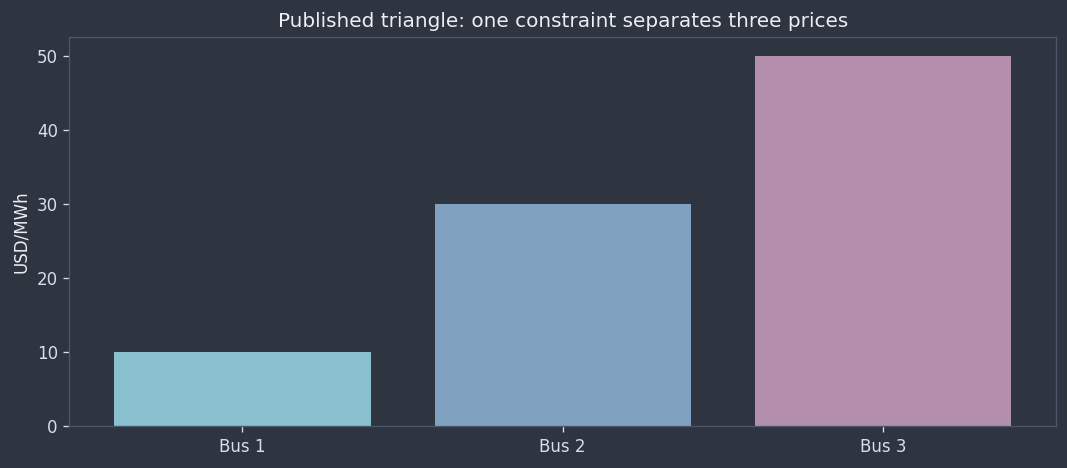

In [3]:
epsilon = 1e-4
marginals = []
for bus in range(3):
    demand = result['demand_mw'].copy()
    demand[bus] += epsilon
    marginals.append((dispatch(demand)['cost_usd_hour']-result['cost_usd_hour'])/epsilon)
np.testing.assert_allclose(marginals, result['lmp_usd_mwh'], atol=1e-5)
load_payment = result['demand_mw'] @ result['lmp_usd_mwh']
generator_payment = result['generation_mw'] @ result['lmp_usd_mwh'][:2]
rent = load_payment-generator_payment
assert abs(rent-150*result['signed_dual'])<1e-7
print({'load_payment_usd': load_payment, 'generator_payment_usd': generator_payment, 'congestion_rent_usd': rent})
plt = setup_plot()
fig, ax = plt.subplots()
ax.bar(['Bus 1','Bus 2','Bus 3'], result['lmp_usd_mwh'], color=['#88C0D0','#81A1C1','#B48EAD'])
ax.set(ylabel='USD/MWh', title='Published triangle: one constraint separates three prices')
fig.tight_layout()
plt.show()

## Exercise and failure case
Reverse the 1→3 transaction. All line flows must reverse sign. Then try
an unbalanced injection: a slack-free PTDF must not hide an unstated source.

In [4]:
np.testing.assert_allclose(flow(-transaction), -flow(transaction))
try:
    flow([1,0,0])
except ValueError as exc:
    print('Expected rejection:', exc)
else:
    raise AssertionError('Unbalanced injection accepted')

Expected rejection: Three finite balanced injections required


## What this does not establish
This is the book's lossless continuous DC model. It does not model commitment,
losses, funding shortfalls, or an actual ISO grid. Nonnegative directional
inequality duals and a signed net constraint coefficient are distinct objects.